##### In this notebook, the two methods for extending the base period of a travelling wave are explored and compared

The methods are:
- Tiling, where one adds a copy to the end of the wave-array
- Padding, where one simply adds zeros (or an appropriate value) to the array


In [10]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *
from camera.lsmCamera import LSM
from solvers.help import *

from waves.waveGenCamera import *

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [11]:
# General set-up:
L = 4*np.pi
N = 2**7
dt = 1e-3

c1 = Camera(L,N,dt)

T=0.5

In [12]:
# Wave set-up
P = 2*np.pi
amp = 1
mean = 0

wp = KdVNewton(P,amp,mean,c1)
wp.solve_w_continuation()

phi = wp.get_physical(wp.phi_hat_mid)

x = np.linspace(-P/2, P/2, N//2)
k = nf.rfftfreq(N//2, c1.dx)*2*np.pi

#### Tiling 
As seen in the cnoidal1 notebook, the waves generated are of the form of a theoretical travelling wave for the KdV equation. 
When the field of view $L$ is a whole multiple $m$ of the wave-period $P$, tiling the wave uses the periodic assumption and looks at $m$ periods of the wave crossing $L$. 
This has the same effect as saying only every $m$-th Fourier mode has a non-zero value. 

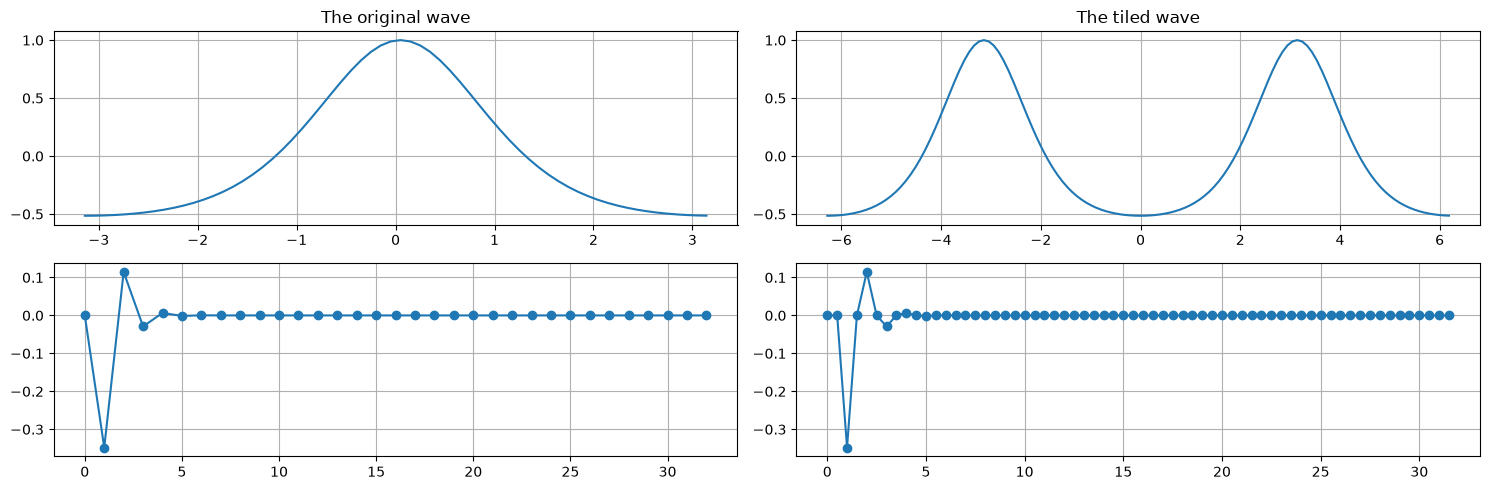

In [28]:
m = int(L//P) # assuming it is integer
phi_tiled = np.tile(phi,m)

fig, ax = plt.subplots(2,2, figsize = (15,5))
ax[0,0].set_title("The original wave")
ax[0,1].set_title("The tiled wave")


ax[0,0].plot(x,phi)
ax[0,1].plot(c1.x, np.tile(phi,2))

ax[0,0].grid()
ax[0,1].grid()

ax[1,0].plot(k,wp.phi_hat_mid.real, '-o')
ax[1,1].plot(c1.k[:N//2], nf.fft(phi_tiled).real[:N//2]/(N), '-o')

ax[1,0].grid()
ax[1,1].grid()

fig.tight_layout()

plt.show()


As the wave is tiled there is no - added - radiation in the forward solution. <br>
Tiling can also be added post solving forward lowering the computation cost.